In [7]:
user_data

,User,Gender,Age,Total.value.sold,Login.days.in.last.30.days,Video_Watched_Minutes_Daily,Number_of_Videos_Uploaded,Account.Total.Likes,Total.Subscribers,Video_Categories_Favourite
0,1,Male,48,646.10,29,117,19,8276,2960,Comedy
1,2,Male,38,590.35,21,181,3,6845,984,Sports
2,3,Female,24,590.29,23,60,4,5886,1604,News
3,4,Male,52,1297.06,1,238,27,8584,3556,Sports
4,5,Male,17,242.70,3,33,0,10688,2560,DIY
5,6,Male,30,436.18,18,95,7,11253,3600,Music
6,7,Male,48,859.16,25,185,6,6730,4456,News
7,8,Male,28,852.29,10,117,9,6403,3518,Education
8,9,Female,32,569.96,22,107,2,10362,2310,Education
9,10,Male,20,1833.37,26,148,21,13120,6136,Education


In [4]:
import pandas as pd
import matplotlib.pyplot as plt
user_data=pd.read_csv("users.csv")
video_data=pd.read_csv("short_video.csv")

                Click  Watch.to.end.%  Click.Through
AI.Use.Level                                        
AI assisted   21093.0            49.0           18.0
AI generated  21958.0            43.0           11.0
No Use        21554.0            60.0           25.0
                     Click  Watch.to.end.%  Click.Through
AI.Use.Level                                             
AI assisted   14685.730134       19.378171       4.137652
AI generated  15322.577664       19.185336       4.884993
No Use        16220.460515       18.620156       3.385719


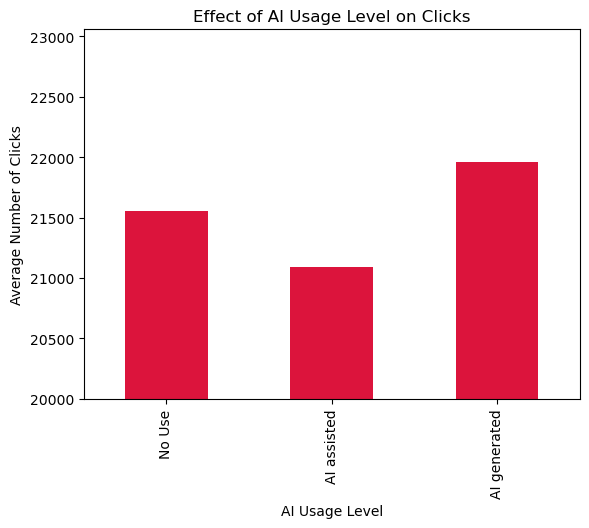

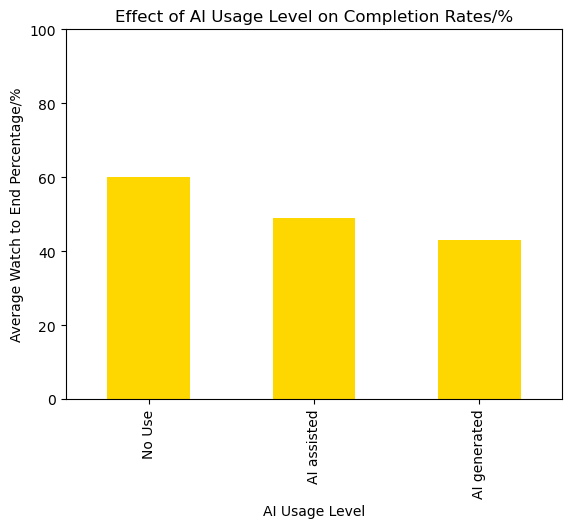

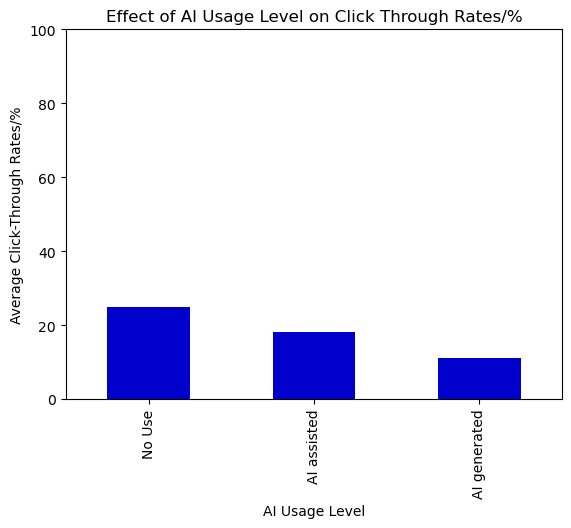

In [72]:
#How does AI usage affect video performance metrics? 
#You can compare click through rates, completion rates, and total clicks between different level of AI use.
%matplotlib inline
#Group by AI Usage level column,filter list of columns to find mean of and round to whole number
AI_effects=video_data.groupby("AI.Use.Level")[["Click","Watch.to.end.%","Click.Through"]].mean().round() 
print(AI_effects)
print(video_data.groupby("AI.Use.Level")[["Click","Watch.to.end.%","Click.Through"]].std())

#Reorder the rows 
desired_order=["No Use","AI assisted","AI generated"]
AI_effects=AI_effects.reindex(desired_order)

#Plot the data in three bar graphs, set limit for y axis to better proportion the graph, label x and y-axes
AI_effects["Click"].plot(kind="bar",color="crimson",title="Effect of AI Usage Level on Clicks").set_ylim(20000)
plt.ylabel("Average Number of Clicks")
plt.xlabel("AI Usage Level")
plt.show()
AI_effects["Watch.to.end.%"].plot(kind="bar", color="gold", title="Effect of AI Usage Level on Completion Rates/%").set_ylim(0,100)
plt.ylabel("Average Watch to End Percentage/%")
plt.xlabel("AI Usage Level")
plt.show()
AI_effects["Click.Through"].plot(kind="bar",color="mediumblue",title="Effect of AI Usage Level on Click Through Rates/%").set_ylim(0,100)
plt.ylabel("Average Click-Through Rates/%")
plt.xlabel("AI Usage Level")
plt.show()

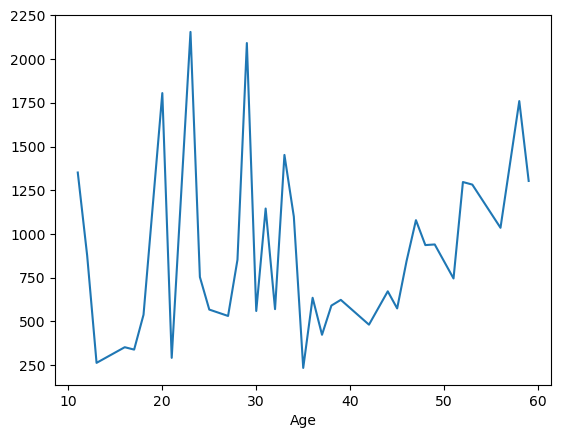

C:\Users\woonc\AppData\Local\Temp\ipykernel_24720\3368386196.py:7: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  user_sold=user_data.groupby("Age_range")["Total.value.sold"].mean().round()


Age_range
11-20     867.0
21-30     986.0
31-40     882.0
41-50     822.0
51-60    1213.0
Name: Total.value.sold, dtype: float64


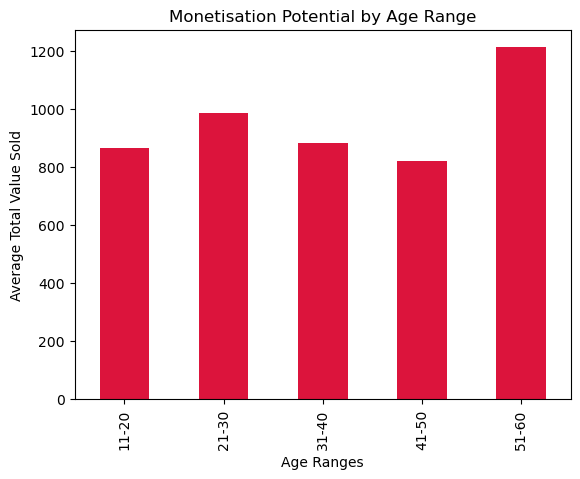

Gender
Female    947.0
Male      954.0
Name: Total.value.sold, dtype: float64


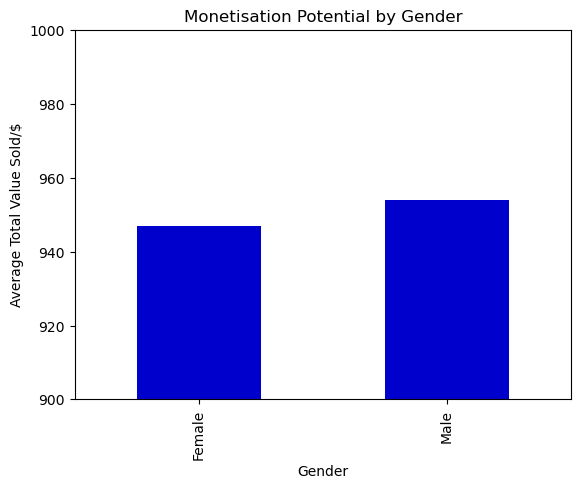

In [76]:
user_data.groupby("Age")["Total.value.sold"].mean().plot.line(x="Age",y="Total.value.sold")
plt.show()

groups=[10,20,30,40,50,60]
labels=["11-20","21-30","31-40","41-50","51-60"]
user_data["Age_range"]=pd.cut(user_data["Age"],bins=groups,labels=labels)
user_sold=user_data.groupby("Age_range")["Total.value.sold"].mean().round()

print(user_sold)
user_sold.plot(kind="bar",x="Age",y="Total.value.sold",color="crimson",title="Monetisation Potential by Age Range")
plt.ylabel("Average Total Value Sold")
plt.xlabel("Age Ranges")
plt.show()

user_sold=user_data.groupby("Gender")["Total.value.sold"].mean().round()
print(user_sold)
user_sold.plot(kind="bar",x="Gender",y="Total.value.sold",color="mediumblue",title="Monetisation Potential by Gender").set_ylim(900,1000)
plt.ylabel("Average Total Value Sold/$")
plt.xlabel("Gender")
plt.show()

In [1]:
user_sold_f=user_data.loc[(user_data["Gender"]=="Female"),"Total.value.sold"]
user_sold_m=user_data.loc[user_data["Gender"]=="Male","Total.value.sold"]
user_sold_f.plot(kind="box",title="Monetisation Potential by female")
plt.show()
user_sold_m.plot(kind="box",title="Monetisation Potential by male")
plt.show()

NameError: name 'user_data' is not defined

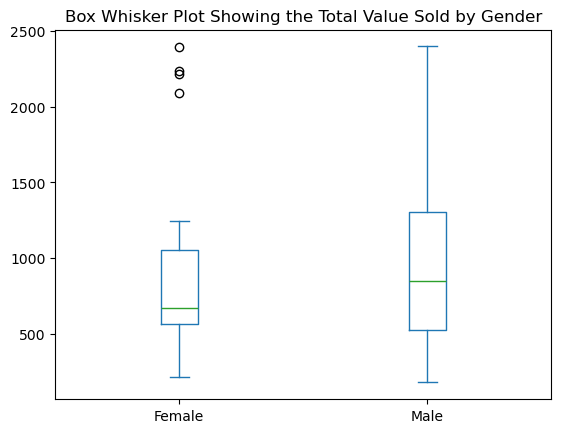

In [112]:
user_data.plot(kind="box",column="Total.value.sold", by="Gender")
plt.title("Box Whisker Plot Showing the Total Value Sold by Gender")
plt.show()